# Tagesmitteltemperatur im Jahresvergleich

Das Diagramm legt die täglichen DWD-Mitteltemperaturen für Berlin-Dahlem jahresweise übereinander. Die x-Achse zeigt den Jahresverlauf von Januar bis Dezember; fehlende Messwerte bleiben als Lücken sichtbar. 2026 ist nur bis zum letzten vorhandenen DWD-Tag enthalten.

## Daten laden und Kalenderverlauf vorbereiten

Der 29. Februar wird im Kalendervergleich beibehalten; dadurch können Nicht-Schaltjahre an diesem Tag eine kleine Linienlücke haben.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

csv_datei = Path("DWD_Berlin_Dahlem_Tagesdaten_2020_heute.csv")
wetter = pd.read_csv(csv_datei, parse_dates=["datum"])
wetter["jahr"] = wetter["datum"].dt.year
wetter["kalendertag"] = pd.to_datetime("2000-" + wetter["datum"].dt.strftime("%m-%d"))
temperatur_nach_jahr = wetter.pivot_table(
    index="kalendertag",
    columns="jahr",
    values="temp_durch_c",
    aggfunc="mean",
)

print(f"Zeitraum: {wetter['datum'].min():%d.%m.%Y} bis {wetter['datum'].max():%d.%m.%Y}")
print("Jahre im Vergleich:", ", ".join(map(str, temperatur_nach_jahr.columns)))

Zeitraum: 01.01.2020 bis 01.11.2026
Jahre im Vergleich: 2020, 2021, 2022, 2023, 2024, 2025, 2026


## Linien nach Jahr

Jedes Jahr erhält eine eigene Farbe. Die Darstellung verwendet die Tagesmitteltemperatur in °C.

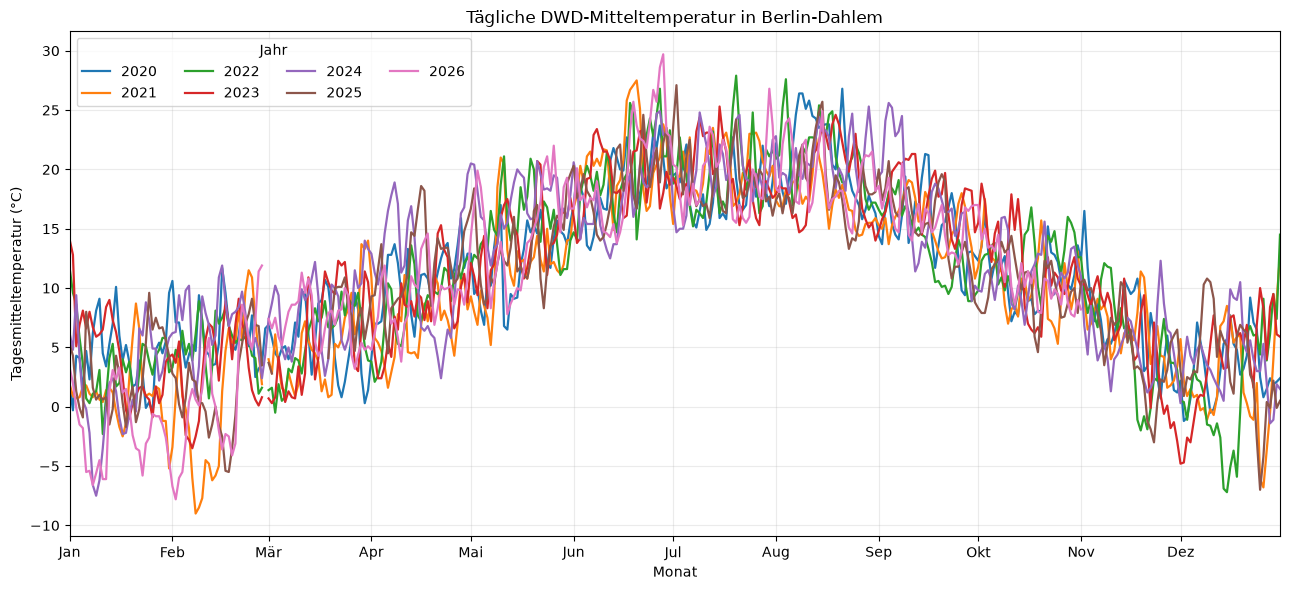

In [2]:
fig, ax = plt.subplots(figsize=(13, 6))

for jahr in temperatur_nach_jahr.columns:
    ax.plot(
        temperatur_nach_jahr.index,
        temperatur_nach_jahr[jahr],
        label=str(jahr),
        linewidth=1.6,
    )

monatsanfang = pd.to_datetime([f"2000-{monat:02d}-01" for monat in range(1, 13)])
ax.set_xticks(monatsanfang)
ax.set_xticklabels(["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"])
ax.set_xlim(pd.Timestamp("2000-01-01"), pd.Timestamp("2000-12-31"))
ax.set_title("Tägliche DWD-Mitteltemperatur in Berlin-Dahlem")
ax.set_xlabel("Monat")
ax.set_ylabel("Tagesmitteltemperatur (°C)")
ax.grid(True, alpha=0.25)
ax.legend(title="Jahr", ncol=4)
fig.tight_layout()
plt.show()

## Zwischenjährliche Streuung 2020–2025

Die Fläche zeigt den Mittelwert aller sechs Jahre ± eine Standardabweichung je Kalendertag. Darunter wird die tägliche Standardabweichung direkt dargestellt. Für jeden Tag werden nur vorhandene DWD-Messwerte verwendet; 2026 bleibt ausgeschlossen, damit ausschließlich vollständige Jahre verglichen werden.

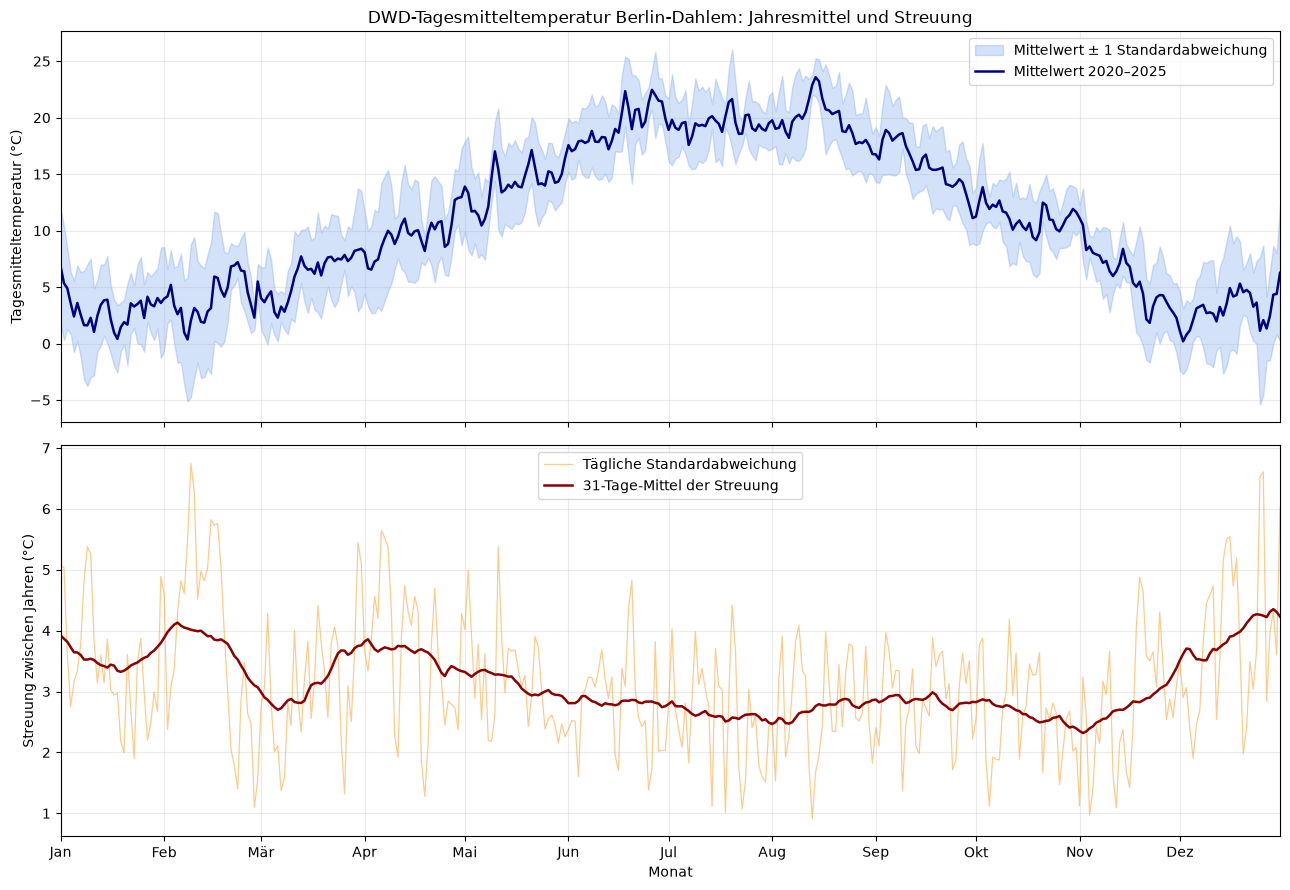

Verglichene Jahre: 2020, 2021, 2022, 2023, 2024, 2025
Gültige Jahreswerte je Kalendertag: 2 bis 6


In [3]:
wetter_2020_2025 = wetter[wetter["jahr"].between(2020, 2025)].copy()
streuung_nach_jahr = wetter_2020_2025.pivot_table(
    index="kalendertag",
    columns="jahr",
    values="temp_durch_c",
    aggfunc="mean",
)
mittelwert = streuung_nach_jahr.mean(axis=1)
standardabweichung = streuung_nach_jahr.std(axis=1)
standardabweichung_geglattet = standardabweichung.rolling(
    window=31, center=True, min_periods=1
).mean()
kalendertage = standardabweichung.index.to_pydatetime()
monatsanfang = pd.to_datetime([f"2000-{monat:02d}-01" for monat in range(1, 13)])
monatsnamen = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
axes[0].fill_between(
    kalendertage,
    (mittelwert - standardabweichung).to_numpy(),
    (mittelwert + standardabweichung).to_numpy(),
    color="cornflowerblue",
    alpha=0.28,
    label="Mittelwert ± 1 Standardabweichung",
)
axes[0].plot(kalendertage, mittelwert.to_numpy(), color="navy", linewidth=1.8, label="Mittelwert 2020–2025")
axes[0].set_ylabel("Tagesmitteltemperatur (°C)")
axes[0].set_title("DWD-Tagesmitteltemperatur Berlin-Dahlem: Jahresmittel und Streuung")
axes[0].legend()
axes[0].grid(True, alpha=0.25)

axes[1].plot(
    kalendertage,
    standardabweichung.to_numpy(),
    color="darkorange",
    alpha=0.45,
    linewidth=0.9,
    label="Tägliche Standardabweichung",
)
axes[1].plot(
    kalendertage,
    standardabweichung_geglattet.to_numpy(),
    color="darkred",
    linewidth=1.8,
    label="31-Tage-Mittel der Streuung",
)
axes[1].set_ylabel("Streuung zwischen Jahren (°C)")
axes[1].set_xlabel("Monat")
axes[1].legend()
axes[1].grid(True, alpha=0.25)
axes[1].set_xticks(monatsanfang)
axes[1].set_xticklabels(monatsnamen)
axes[1].set_xlim(pd.Timestamp("2000-01-01"), pd.Timestamp("2000-12-31"))

fig.tight_layout()
plt.show()

print(f"Verglichene Jahre: {', '.join(map(str, streuung_nach_jahr.columns))}")
print(f"Gültige Jahreswerte je Kalendertag: {streuung_nach_jahr.notna().sum(axis=1).min()} bis {streuung_nach_jahr.notna().sum(axis=1).max()}")